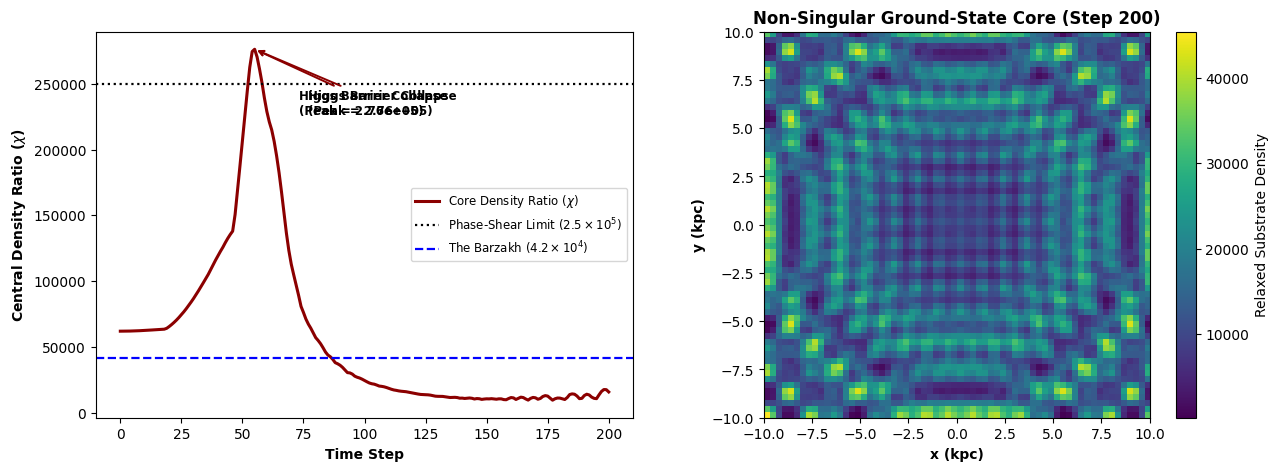

=== COMPUTED OUTPUTS FOR TABLE 5 ===
Step 0 Initial Core Chi : 6.20e+04
Peak Compression Chi    : 2.76e+05 (at Step 55)
Step 200 Relaxed Chi    : 1.58e+04


In [12]:

import numpy as np
import matplotlib.pyplot as plt

N = 64
L = 20.0
dx = L / N
x = np.linspace(-L/2, L/2, N, endpoint=False)
X, Y = np.meshgrid(x, x, indexing='ij')
R = np.sqrt(X**2 + Y**2)

k_1d = 2 * np.pi * np.fft.fftfreq(N, d=dx)
KX, KY = np.meshgrid(k_1d, k_1d, indexing='ij')
K2 = KX**2 + KY**2
K2_safe = np.where(K2 == 0, 1.0, K2)

chi_bg = 1.2e4
chi_core_0 = 5.0e4
psi = np.sqrt(chi_bg + chi_core_0 * np.exp(-(R / 3.2)**2)).astype(np.complex128)
total_norm = np.sum(np.abs(psi)**2)

chi_barzakh = 4.2e4
chi_shear = 2.5e5

dt = 0.025
steps = 200
kinetic_phase = np.exp(-0.5j * K2 * dt)

central_chi_hist = []
higgs_melted = False

for step in range(steps + 1):
    chi = np.abs(psi)**2
    chi_center = float(np.max(chi[R < 1.5]))
    central_chi_hist.append(chi_center)

    if chi_center >= chi_shear:
        higgs_melted = True

    delta_chi_k = np.fft.fftn(chi - np.mean(chi))
    Phi_k = -4.0 * np.pi * 0.14 * delta_chi_k / K2_safe
    Phi_k.flat = 0.0
    Phi_grav = np.real(np.fft.ifftn(Phi_k))

    if not higgs_melted:
        V_higgs = -1.8 * np.tanh((chi - chi_barzakh) / 1.5e4)
        g_eff = 1.2e-5
    else:
        V_higgs = 0.0
        g_eff = 6.5e-5

    V_total = Phi_grav + V_higgs + g_eff * chi
    psi *= np.exp(-0.5j * V_total * dt)
    psi = np.fft.ifftn(np.fft.fftn(psi) * kinetic_phase)
    chi_mid = np.abs(psi)**2
    V_total_mid = Phi_grav + V_higgs + g_eff * chi_mid
    psi *= np.exp(-0.5j * V_total_mid * dt)
    psi *= np.sqrt(total_norm / np.sum(np.abs(psi)**2))

chi_end = np.abs(psi)**2
peak_step = int(np.argmax(central_chi_hist))
peak_val = float(np.max(central_chi_hist))
init_val = float(np.array(central_chi_hist).item(0))
end_val = float(np.array(central_chi_hist).item(-1))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))
ax1.plot(range(steps + 1), central_chi_hist, color='#8b0000', lw=2.2, label=r'Core Density Ratio ($\chi$)')
ax1.axhline(chi_shear, color='black', ls=':', lw=1.6, label=r'Phase-Shear Limit ($2.5 \times 10^5$)')
ax1.axhline(chi_barzakh, color='blue', ls='--', lw=1.6, label=r'The Barzakh ($4.2 \times 10^4$)')
ax1.annotate(f'Higgs Barrier Collapse\n(Peak = {peak_val:.2e})', xy=(peak_step, peak_val), xytext=(peak_step + 18, peak_val * 0.82),
             arrowprops=dict(arrowstyle='->', color='#8b0000', lw=1.4), fontweight='bold', fontsize=8.5)
ax1.set_xlabel('Time Step', fontweight='bold')
ax1.set_ylabel(r'Central Density Ratio ($\chi$)', fontweight='bold')
ax1.annotate(f'Higgs Barrier Collapse\n(Peak = {peak_val:.2e})', xy=(peak_step, peak_val), xytext=(peak_step + 22, peak_val * 0.82),
             arrowprops=dict(arrowstyle='->', color='#8b0000', lw=1.4), fontweight='bold', fontsize=8.5)
ax1.legend(loc='center right', fontsize=8.5)

im = ax2.imshow(chi_end, extent=[-L/2, L/2, -L/2, L/2], origin='lower', cmap='viridis')
plt.colorbar(im, ax=ax2, label='Relaxed Substrate Density')
ax2.set_xlabel('x (kpc)', fontweight='bold')
ax2.set_ylabel('y (kpc)', fontweight='bold')
ax2.set_title('Non-Singular Ground-State Core (Step 200)', fontweight='bold')

plt.tight_layout()
plt.savefig('sim2_bh_recycling.png', dpi=300)
plt.show()

print("=== COMPUTED OUTPUTS FOR TABLE 5 ===")
print(f"Step 0 Initial Core Chi : {init_val:.2e}")
print(f"Peak Compression Chi    : {peak_val:.2e} (at Step {peak_step})")
print(f"Step 200 Relaxed Chi    : {end_val:.2e}")